# UrbanTales — Realistic Profile EDA (Google Colab)

**Purpose:** Reproducible EDA of realistic UrbanTales *profile CSVs* only.

This notebook includes:
- Profile-only ZIP inventory and expected-count checks
- Case-name parsing and optional metadata/catalog join
- Missingness, duplicate, row-count, and z=0 diagnostics
- Vertical profiles and **U at z = 1.75 m** (interpolated per case)
- Per-case target-like summaries using the pedestrian-height profile value
- Direction-suffix summaries clearly labelled exploratory
- `cdz` missing-gap position/length diagnostics
- Case-level Spearman correlations to avoid treating every height row as independent
- Physics checks for `Mom = Tuw + Duw` and `Km = -Mom/uGrad`
- Exports and a downloadable results bundle

**Scope limits:** profile CSVs cannot establish spatial-map alignment, pedestrian-height map distributions, spatial correlation length, buildings-with-wind-values, or simulation run duration. Those require `_topo`, `_ped.nc`, `.p3d`, and/or `_ts.nc` files. Actual wind direction must be verified from `.p3d`, not inferred solely from `_dNN`.

**Team handbook rules used here:** remove the final profile row near 131 m for analysis; retain raw data; investigate quality-check discrepancies instead of silently fixing them.


## 1. Upload the realistic ZIP

In [35]:

from pathlib import Path
import zipfile

# Find ZIP files in Downloads
downloads = Path.home() / "Downloads"
zip_files = sorted(downloads.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError("No ZIP files found in Downloads.")

# Show available ZIP files
print("Choose your realistic profile dataset ZIP:\n")

for i, file in enumerate(zip_files):
    print(f"{i}: {file.name}")

# Select the dataset
choice = int(input("\nEnter the number of your realistic dataset ZIP: "))

if not 0 <= choice < len(zip_files):
    raise ValueError("Invalid selection. Run this cell again.")

ZIP_PATH = zip_files[choice]

# Validate the selected ZIP
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad_file = zf.testzip()

    if bad_file is not None:
        raise ValueError(f"Corrupted file inside ZIP: {bad_file}")

    csv_files = [
        name for name in zf.namelist()
        if Path(name).name.lower().startswith("profile-")
        and name.lower().endswith(".csv")
    ]

print("\nSelected:", ZIP_PATH.name)
print(f"Size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("Profile CSV files found:", len(csv_files))
print("ZIP is valid!")

# Warn if the archive doesn't contain the expected number of cases
if len(csv_files) != 314:
    print(f"WARNING: Expected 314 realistic profile CSVs, found {len(csv_files)}.")


Choose your realistic profile dataset ZIP:

0: 4e4e8a937d6b484e8884953cf1341b18.zip
1: 69e7391364f78_drive_download_20260421t084412z_3_001.zip
2: 7bf8c65481704bffb5ab62b49a90cd20.zip
3: Cancelled_Diverted_2023.csv.zip
4: Lab_4_Student_todo.zip
5: MCA_Modern_Computer_Architecture_Midsem_React_Website.zip
6: ProfileDemo-main.zip
7: UrbanTales_Realistic_EDA_Results (1).zip
8: UrbanTales_Realistic_EDA_Results (2).zip
9: UrbanTales_Realistic_EDA_Results (3).zip
10: UrbanTales_Realistic_EDA_Results.zip
11: VSCode-darwin-universal.zip
12: Zomato Dataset 2.csv.zip
13: Zomato Dataset.csv.zip
14: aa559203bbfc4e789dafa54c66dfc32d.zip
15: aml_lab-main (1).zip
16: aml_lab-main (2).zip
17: aml_lab-main (3).zip
18: aml_lab-main (4).zip
19: aml_lab-main (5).zip
20: aml_lab-main (6).zip
21: aml_lab-main (7).zip
22: aml_lab-main (8).zip
23: aml_lab-main.zip
24: archive (1).zip
25: archive.zip
26: bank+marketing.zip
27: c544629fd6b14df39ef8c177e26f9430.zip
28: cardio_train.csv.zip
29: daikibo-telemetry-d

## 2. Imports and configuration

In [36]:
from pathlib import Path
import zipfile
import re
import warnings
import inspect
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

OUTPUT_DIR = Path("realistic_eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

EXPECTED_CASES = 314
EXPECTED_ROWS_PER_PROFILE = 130
PEDESTRIAN_HEIGHT_M = 1.75
HANDBOOK_REALISTIC_MEDIAN_U175 = 1.83  # rough map-based median U/u* from the team handbook

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| matplotlib:", matplotlib.__version__)


pandas: 2.2.3 | numpy: 2.2.6 | matplotlib: 3.10.9


## 3. Inventory only `profile-*.csv` files and combine them

In [37]:
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    profile_files = [
        name for name in zf.namelist()
        if not name.endswith("/") and Path(name).name.lower().startswith("profile-")
        and name.lower().endswith(".csv")
    ]
    if not profile_files:
        raise ValueError("No profile-*.csv files found. Check the ZIP contents.")

    frames, inventory_rows = [], []
    for member in profile_files:
        with zf.open(member) as file_obj:
            df = pd.read_csv(file_obj)

        case_name = Path(member).name
        case_name = case_name.removeprefix("profile-").removesuffix(".csv")
        df["case"] = case_name
        frames.append(df)

        inventory_rows.append({
            "case": case_name,
            "file": member,
            "rows": len(df),
            "columns_without_case": len(df.columns) - 1,
            "z_min": df["z"].min() if "z" in df.columns else np.nan,
            "z_max": df["z"].max() if "z" in df.columns else np.nan,
        })

inventory = pd.DataFrame(inventory_rows)
raw = pd.concat(frames, ignore_index=True)

print(f"Profile CSVs: {len(profile_files)}")
print(f"Unique cases: {raw['case'].nunique()}")
print("Raw combined shape:", raw.shape)
display(inventory.head())
display(inventory["rows"].value_counts().sort_index().rename_axis("rows_per_file").to_frame("case_count"))

# Hard checks produce visible warnings rather than silently assuming the archive is complete.
if raw["case"].nunique() != EXPECTED_CASES:
    warnings.warn(f"Expected {EXPECTED_CASES} cases, found {raw['case'].nunique()}. Verify the selected ZIP.")
if not (inventory["rows"] == EXPECTED_ROWS_PER_PROFILE).all():
    warnings.warn("At least one profile CSV does not contain 130 rows. Inspect the inventory.")


Profile CSVs: 314
Unique cases: 314
Raw combined shape: (40820, 32)


,case,file,rows,columns_without_case,z_min,z_max
0,AR-BA-U1_d00,AR-BA-U1_d00/profile-AR-BA-U1_d00.csv,130,31,0.0,131.497011
1,AR-BA-U2_d00,AR-BA-U2_d00/profile-AR-BA-U2_d00.csv,130,31,0.0,131.497011
2,AR-BA-V1_d00,AR-BA-V1_d00/profile-AR-BA-V1_d00.csv,130,31,0.0,131.497011
3,AU-Ade-V1_d00,AU-Ade-V1_d00/profile-AU-Ade-V1_d00.csv,130,31,0.0,131.497011
4,AU-Ade-V1_d90,AU-Ade-V1_d90/profile-AU-Ade-V1_d90.csv,130,31,0.0,131.497011


,case_count
rows_per_file,
130,314


## 4. Parse case names and identify known QC flags

In [38]:
def parse_case_name(case):
    # Heuristic only; official metadata/catalog should be used for reliable city/group fields.
    text = str(case)
    match = re.search(r"_d(\d+)$", text)
    direction_suffix = int(match.group(1)) if match else np.nan
    base = re.sub(r"_d\d+$", "", text)
    parts = base.split("-")
    return pd.Series({
        "case_base_without_direction": base,
        "direction_suffix_deg": direction_suffix,
        "country_code_guess": parts[0] if parts else np.nan,
        "series_or_city_guess": "-".join(parts[1:-1]) if len(parts) > 2 else np.nan,
        "final_case_token": parts[-1] if len(parts) >= 2 else np.nan,
    })

parsed_names = inventory["case"].apply(parse_case_name)
inventory = pd.concat([inventory, parsed_names], axis=1)

def qc_flag(case):
    s = str(case).lower().replace("_", "-")
    flags = []
    if "cn-bei-v1" in s:
        flags.append("CN-Bei-V1 name direction may be offset 90 degrees from forcing; verify with .p3d")
    if s.startswith("jp-tok-v4-d00"):
        flags.append("short/incomplete run reported; verify duration with _ts.nc/.p3d")
    building_wind_cases = [
        "ug-ug-u1", "ug-ug-u2", "ug-ug-u3", "np-np-u1", "au-mel-u9"
    ]
    if any(s.startswith(prefix) for prefix in building_wind_cases):
        flags.append("buildings may hold wind values; check using _ped.nc and _topo")
    return "; ".join(flags)

inventory["known_qc_flag_to_verify"] = inventory["case"].map(qc_flag)
print("Cases with handbook QC flags to verify:")
display(inventory.loc[inventory["known_qc_flag_to_verify"] != "",
                      ["case", "known_qc_flag_to_verify"]])


Cases with handbook QC flags to verify:


,case,known_qc_flag_to_verify
44,AU-Mel-U9_d00,buildings may hold wind values; check using _p...
144,JP-Tok-V4_d00,short/incomplete run reported; verify duration...
191,NP-NP-U1_d00,buildings may hold wind values; check using _p...
250,UG-UG-U1_d00,buildings may hold wind values; check using _p...
251,UG-UG-U2_d00,buildings may hold wind values; check using _p...
252,UG-UG-U3_d00,buildings may hold wind values; check using _p...


## 5. Optional join to official metadata/catalog

In [39]:

from pathlib import Path
import pandas as pd
from IPython.display import display

downloads = Path.home() / "Downloads"

# Find catalog and metadata CSV files
csv_files = sorted(downloads.glob("*.csv"))
catalog_files = [
    f for f in csv_files
    if "portal_to_metadata_map" not in f.name.lower()
    and any(word in f.name.lower()
            for word in ["catalog", "metadata", "urbantales"])
]

if not catalog_files:
    raise FileNotFoundError(
        "No catalog/metadata CSV files found in Downloads."
    )

print("Choose the official catalog/metadata CSV:")
for i, f in enumerate(catalog_files):
    print(f"{i}: {f.name}")

choice = int(input("Enter file number: "))
metadata_path = catalog_files[choice]
metadata = pd.read_csv(metadata_path)

print("\nSelected:", metadata_path.name)
print("Columns:", metadata.columns.tolist())

# Find a likely case-ID column
possible_id_cols = [
    "case", "case_id", "name", "folder", "folder_name", "id"
]
CASE_ID_COL = next(
    (c for c in possible_id_cols if c in metadata.columns),
    None
)

if CASE_ID_COL is None:
    print("\nNo standard case-ID column found.")
    print("We need to inspect the catalog's actual columns before joining.")
    display(metadata.head())
else:
    metadata = metadata.rename(columns={CASE_ID_COL: "case"})
    metadata["case"] = metadata["case"].astype(str)

    if metadata["case"].duplicated().any():
        raise ValueError("Duplicate case IDs in catalog; join stopped.")

    before_rows = len(inventory)
    inventory = inventory.merge(
        metadata,
        on="case",
        how="left",
        indicator="_catalog_match",
        validate="many_to_one",
        suffixes=("", "_metadata")
    )

    assert len(inventory) == before_rows

    unmatched = inventory.loc[
        inventory["_catalog_match"] == "left_only", "case"
    ]

    print("Profile cases:", len(inventory))
    print("Unmatched cases:", len(unmatched))
    if len(unmatched):
        display(unmatched.to_frame("unmatched_profile_case"))

    if "split_group" in inventory.columns:
        print(
            "Missing split_group:",
            inventory["split_group"].isna().sum()
        )

    inventory.drop(columns="_catalog_match", inplace=True)


Choose the official catalog/metadata CSV:
0: UrbanTALES-flowdata (1).csv
1: UrbanTALES-flowdata.csv
2: cleaned_metadata_full (6).csv
3: metadata (1).csv
4: metadata.csv

Selected: metadata.csv
Columns: ['NameI', 'NameE', 'Config', 'WD', 'dxdy', 'City', 'State', 'Country', 'Longitude', 'Latitude', '$u_{\\tau}$', 'x-y', 'x/y', 'lp', 'lf', 'gammaH', 'gamma', 'hmean', 'hstd', 'hmax', 'hmin', 'H/h', 'SAR']

No standard case-ID column found.
We need to inspect the catalog's actual columns before joining.


,NameI,NameE,Config,WD,dxdy,City,State,Country,Longitude,Latitude,$u_{\tau}$,x-y,x/y,lp,lf,gammaH,gamma,hmean,hstd,hmax,hmin,H/h,SAR
0,A0625,UA0625_d00,idealized-uniform_d00,0,0.5,NaN,NaN,NaN,NaN,NaN,0.210141,320m x 192m,1.666667,0.062500,0.062500,31.4531,0.7876,16.0,0.0,16.0,16.0,8.0,A
1,A1111,UA1111_d00,idealized-uniform_d00,0,0.5,NaN,NaN,NaN,NaN,NaN,0.209432,240m x 144m,1.666667,0.111111,0.111111,21.2917,0.7112,16.0,0.0,16.0,16.0,8.0,A
2,A1600,UA16_d00,idealized-uniform_d00,0,0.5,NaN,NaN,NaN,NaN,NaN,0.208715,200m x 120m,1.666667,0.160000,0.160000,16.1625,0.6481,16.0,0.0,16.0,16.0,8.0,A
3,A2500,UA25_d00,idealized-uniform_d00,0,0.5,NaN,NaN,NaN,NaN,NaN,0.207391,160m x 96m,1.666667,0.250000,0.250000,10.9688,0.5502,16.0,0.0,16.0,16.0,8.0,A
4,A3500,UA35_d00,idealized-uniform_d00,0,0.5,NaN,NaN,NaN,NaN,NaN,0.205891,135m x 81m,1.666667,0.351166,0.351166,7.6644,0.4559,16.0,0.0,16.0,16.0,8.0,A


## 6. Inspect columns, data types, and descriptive statistics

In [40]:
print("Columns:")
print(raw.columns.tolist())
print("\nData types:")
display(raw.dtypes.astype(str).to_frame("dtype"))
print("\nNumeric descriptive statistics:")
display(raw.select_dtypes(include=np.number).describe().T)


Columns:
['Unnamed: 0', 'z', 'u', 'v', 'w', 'U', 's', 'TKE', 'Duw', 'Tuw', 'Dvw', 'Tvw', 'Mom', 'ILs', 'vel', 'stdS', 'cdz', 'uGrad', 'sgsR', 'sgsM', 'turbT', 'lm', 'dispT', 'presT', 'shearP', 'wakeP', 'formA', 'Km', 'cklk', 'lece', 'cmu', 'case']

Data types:


,dtype
Unnamed: 0,int64
z,float64
u,float64
v,float64
w,float64
U,float64
s,float64
TKE,float64
Duw,float64
Tuw,float64



Numeric descriptive statistics:


/opt/homebrew/lib/python3.10/site-packages/numpy/_core/_methods.py:52: RuntimeWarning: invalid value encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,40820.0,6.450000e+01,3.752712e+01,0.000000e+00,3.200000e+01,6.450000e+01,9.700000e+01,1.290000e+02
z,40820.0,3.601898e+01,2.699373e+01,0.000000e+00,1.575000e+01,3.200000e+01,4.825000e+01,1.314970e+02
u,40506.0,4.162728e+00,4.032777e+00,-7.785479e-01,2.068004e-01,2.930080e+00,7.558129e+00,1.931768e+01
v,40506.0,2.439449e+00,3.322845e+00,2.231210e-02,2.353583e-01,7.354739e-01,3.285088e+00,1.788554e+01
w,40506.0,-1.300754e-04,3.096431e-04,-4.715095e-03,-1.348309e-04,-1.351680e-09,1.634372e-10,1.545263e-04
U,40506.0,6.258475e+00,3.466488e+00,9.810301e-01,2.885316e+00,6.239201e+00,8.949618e+00,1.931861e+01
s,40506.0,3.474257e+16,7.544663e+17,5.235023e-02,5.855233e-02,5.948790e-02,6.113939e-02,2.890721e+19
TKE,40506.0,1.918130e+00,6.779849e+00,-1.867499e+02,1.853579e+00,2.487588e+00,3.074855e+00,5.156755e+00
Duw,40506.0,-7.575102e-02,8.806056e-02,-6.081274e-01,-1.200752e-01,-4.960465e-02,-3.498931e-03,1.557070e-01
Tuw,40192.0,-3.369175e-01,2.865492e-01,-1.155376e+00,-6.014922e-01,-3.132708e-01,-1.418249e-02,4.526635e-02


## 7. Missing values and duplicate checks

,missing_count,missing_percent
cdz,9532,23.53
lm,5360,13.23
presT,942,2.33
turbT,942,2.33
cmu,678,1.67
cklk,678,1.67
Km,628,1.55
formA,628,1.55
shearP,628,1.55
lece,364,0.90


Duplicate complete rows in raw combined table: 0
Unique raw row counts across cases: [130]


,case,file,rows


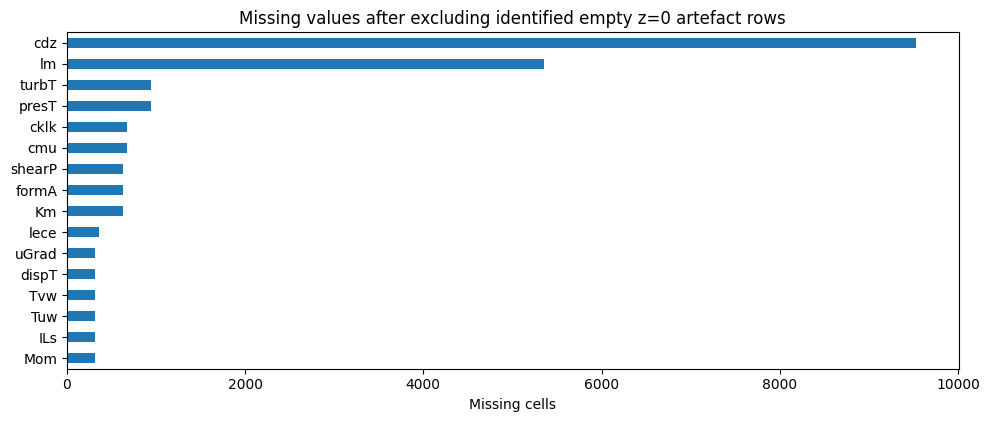

In [41]:
# Identify empty z=0 artefact rows before calculating missingness.
# Ignore index-like fields and sgsR because sgsR may be 0 at z=0 even when other measurements are empty.
IGNORE_FOR_Z0_EMPTY_CHECK = ["case", "z", "Unnamed: 0", "sgsR"]
z0_measurement_columns = [c for c in raw.columns if c not in IGNORE_FOR_Z0_EMPTY_CHECK]
is_z0_for_missing = np.isclose(raw["z"], 0, equal_nan=False)
z0_empty_for_missing = is_z0_for_missing & raw[z0_measurement_columns].isna().all(axis=1)
analysis_for_missing = raw.loc[~z0_empty_for_missing].copy()

measurement_data = analysis_for_missing.drop(columns=["case"])
missing_count = measurement_data.isna().sum().sort_values(ascending=False)
missing_percent = (missing_count / len(measurement_data) * 100).round(2)
missing_table = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
})
missing_table = missing_table[missing_table["missing_count"] > 0]
display(missing_table)

print("Duplicate complete rows in raw combined table:", int(raw.duplicated().sum()))
rows_per_case = raw.groupby("case").size()
print("Unique raw row counts across cases:", sorted(rows_per_case.unique().tolist()))
display(inventory.loc[inventory["rows"] != EXPECTED_ROWS_PER_PROFILE,
                      ["case", "file", "rows"]])

if not missing_table.empty:
    fig, ax = plt.subplots(figsize=(10, max(4, len(missing_table) * 0.27)))
    missing_table["missing_count"].sort_values().plot(kind="barh", ax=ax)
    ax.set_title("Missing values after excluding identified empty z=0 artefact rows")
    ax.set_xlabel("Missing cells")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 8. Diagnose `z = 0` and the final profile level

In [42]:
# Ignore metadata/index-like fields and sgsR when identifying an otherwise empty z=0 row.
# Some files store sgsR=0 at z=0 even when the other measurements are empty.
IGNORE_FOR_Z0_EMPTY_CHECK = ["case", "z", "Unnamed: 0", "sgsR"]
measurement_columns = [
    c for c in raw.columns if c not in IGNORE_FOR_Z0_EMPTY_CHECK
]
is_z0 = np.isclose(raw["z"], 0, equal_nan=False)
z0_empty = is_z0 & raw[measurement_columns].isna().all(axis=1)

print("z=0 rows:", int(is_z0.sum()), "| of which empty and dropped:", int(z0_empty.sum()))
print("Cases with z=0 rows:", raw.loc[is_z0, "case"].nunique())

base = raw.loc[~z0_empty].copy()
clean = pd.concat(
    [group.sort_values("z").iloc[:-1] for _, group in base.groupby("case", sort=False)],
    ignore_index=True
).drop(columns=["Unnamed: 0"], errors="ignore")

print("Raw rows:", len(raw), "| after empty z=0 removal:", len(base),
      "| after final-level removal:", len(clean))
print("Unique retained row counts per case:", clean.groupby("case").size().unique())
print("Minimum retained z:", clean["z"].min())
print("Cases with z=0 still retained (non-empty measurement rows):",
      int(clean.loc[np.isclose(clean["z"], 0), "case"].nunique()))

# Keep an explicit audit table of the z=0 rows and whether they were removed.
z0_audit = raw.loc[is_z0, ["case", "z"] + [c for c in ["sgsR", "cdz", "U", "TKE"] if c in raw.columns]].copy()
z0_audit["empty_measurement_row_dropped"] = z0_empty.loc[z0_audit.index].to_numpy()
display(z0_audit.head(20))


z=0 rows: 314 | of which empty and dropped: 314
Cases with z=0 rows: 314
Raw rows: 40820 | after empty z=0 removal: 40506 | after final-level removal: 40192
Unique retained row counts per case: [128]
Minimum retained z: 0.25
Cases with z=0 still retained (non-empty measurement rows): 0


,case,z,sgsR,cdz,U,TKE,empty_measurement_row_dropped
0,AR-BA-U1_d00,0.0,0.0,NaN,NaN,NaN,True
130,AR-BA-U2_d00,0.0,0.0,NaN,NaN,NaN,True
260,AR-BA-V1_d00,0.0,0.0,NaN,NaN,NaN,True
390,AU-Ade-V1_d00,0.0,0.0,NaN,NaN,NaN,True
520,AU-Ade-V1_d90,0.0,0.0,NaN,NaN,NaN,True
650,AU-Bri-V1_d00,0.0,0.0,NaN,NaN,NaN,True
780,AU-CAN-V3_d00,0.0,0.0,NaN,NaN,NaN,True
910,AU-Can-V1_d00,0.0,0.0,NaN,NaN,NaN,True
1040,AU-Can-V2_d00,0.0,0.0,NaN,NaN,NaN,True
1170,AU-Hob-V1_d00,0.0,0.0,NaN,NaN,NaN,True


## 9. Interpolate `U` at pedestrian height (z = 1.75 m)

In [43]:
def interpolate_at_height(group, variable, target_z=PEDESTRIAN_HEIGHT_M):
    # Use finite z/value pairs and interpolate only within the available vertical range.
    pairs = group[["z", variable]].dropna().sort_values("z")
    pairs = pairs[np.isfinite(pairs["z"]) & np.isfinite(pairs[variable])]
    if len(pairs) < 2:
        return np.nan
    if target_z < pairs["z"].min() or target_z > pairs["z"].max():
        return np.nan
    return float(np.interp(target_z, pairs["z"].to_numpy(), pairs[variable].to_numpy()))

case_rows = []
for case, group in clean.groupby("case", sort=False):
    row = {
        "case": case,
        "profile_U_at_1p75m": interpolate_at_height(group, "U"),
        "profile_TKE_at_1p75m": interpolate_at_height(group, "TKE"),
        "profile_U_mean_all_heights": group["U"].mean(),
        "profile_U_max_all_heights": group["U"].max(),
        "profile_TKE_mean_all_heights": group["TKE"].mean(),
        "profile_TKE_max_all_heights": group["TKE"].max(),
        "z_min": group["z"].min(),
        "z_max": group["z"].max(),
        "levels_after_final_drop": len(group),
    }
    case_rows.append(row)

case_summary = pd.DataFrame(case_rows)
case_summary = case_summary.merge(
    inventory[["case", "direction_suffix_deg", "country_code_guess",
               "series_or_city_guess", "known_qc_flag_to_verify"]].drop_duplicates("case"),
    on="case", how="left"
)
print("Per-case profile U at 1.75 m:")
display(case_summary[["case", "profile_U_at_1p75m", "profile_TKE_at_1p75m"]].head())
display(case_summary[["profile_U_at_1p75m", "profile_TKE_at_1p75m"]].describe().T)


Per-case profile U at 1.75 m:


,case,profile_U_at_1p75m,profile_TKE_at_1p75m
0,AR-BA-U1_d00,2.850546,2.488331
1,AR-BA-U2_d00,2.191042,2.344566
2,AR-BA-V1_d00,1.785856,1.566669
3,AU-Ade-V1_d00,2.486966,1.855240
4,AU-Ade-V1_d90,2.206024,1.922323


,count,mean,std,min,25%,50%,75%,max
profile_U_at_1p75m,314.0,2.032863,0.645483,1.149551,1.655036,1.916471,2.209346,6.582629
profile_TKE_at_1p75m,314.0,1.815216,0.515682,0.891825,1.440215,1.892875,2.076459,4.694832


## 10. Vertical profiles: median and interquartile range

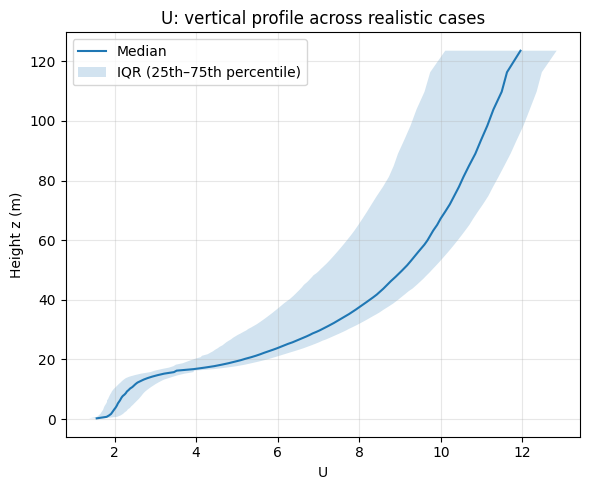

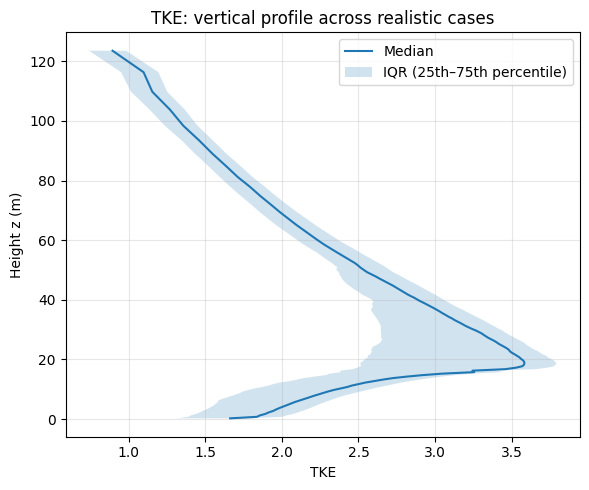

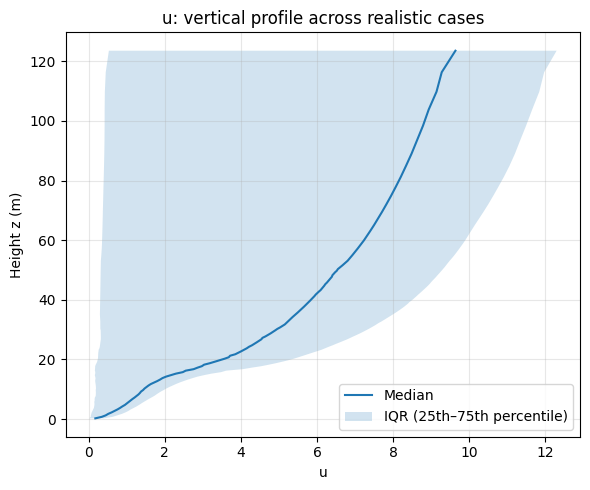

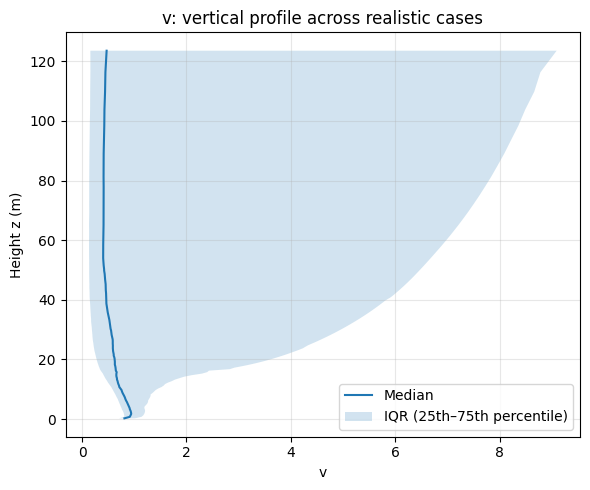

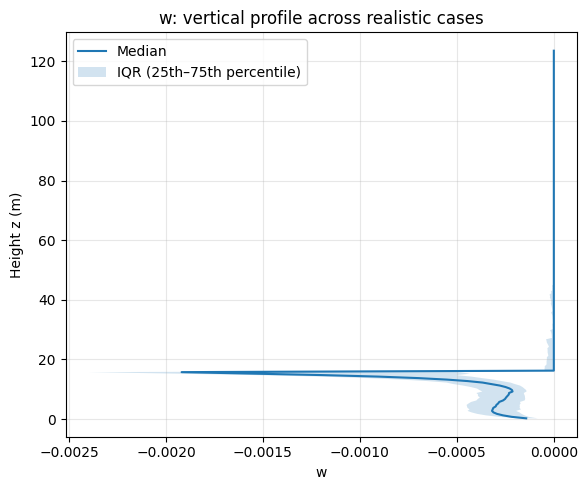

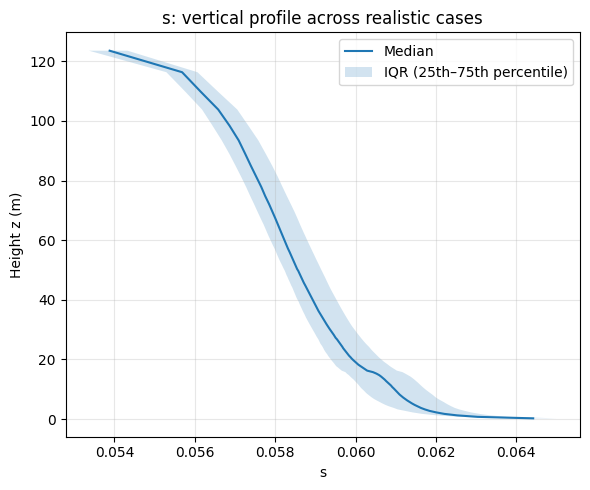

In [44]:
profile_variables = [v for v in ["U", "TKE", "u", "v", "w", "s"] if v in clean.columns]
for variable in profile_variables:
    grouped = clean.groupby("z")[variable].agg(
        median="median",
        q25=lambda values: values.quantile(0.25),
        q75=lambda values: values.quantile(0.75)
    ).reset_index().sort_values("z")

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(grouped["median"], grouped["z"], label="Median")
    ax.fill_betweenx(grouped["z"], grouped["q25"], grouped["q75"],
                     alpha=0.2, label="IQR (25th–75th percentile)")
    ax.set(xlabel=variable, ylabel="Height z (m)",
           title=f"{variable}: vertical profile across realistic cases")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 11. Distribution of per-case `U` at 1.75 m and TKE at 1.75 m

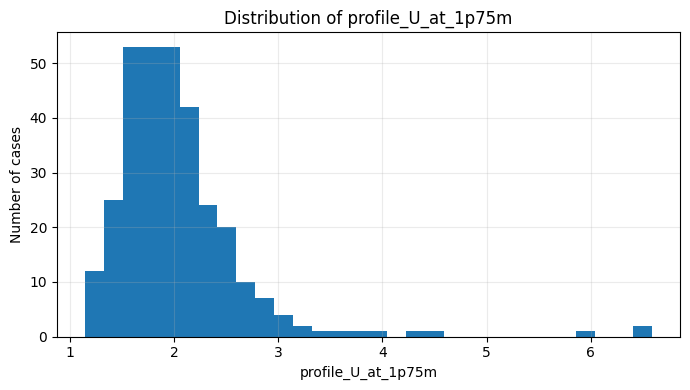

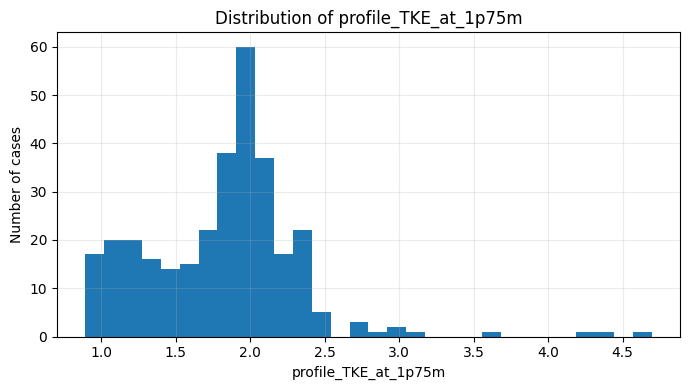

In [45]:
for variable in ["profile_U_at_1p75m", "profile_TKE_at_1p75m"]:
    values = case_summary[variable].dropna()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(values, bins=30)
    ax.set_xlabel(variable)
    ax.set_ylabel("Number of cases")
    ax.set_title(f"Distribution of {variable}")
    ax.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 12. Exploratory case-name direction comparison

,direction_suffix_deg,cases,U_1p75_median,U_1p75_q25,U_1p75_q75,TKE_1p75_median
0,0.0,164,1.924304,1.673285,2.254143,1.925892
1,15.0,18,1.714948,1.549367,1.964634,1.412437
2,30.0,18,1.712117,1.504735,1.996466,1.371353
3,45.0,18,1.684896,1.538574,1.976316,1.273699
4,60.0,1,2.154987,2.154987,2.154987,1.911201
5,75.0,1,2.083929,2.083929,2.083929,1.927425
6,90.0,78,1.927176,1.678628,2.357753,2.013167
7,105.0,1,2.119202,2.119202,2.119202,1.925721
8,120.0,1,2.202688,2.202688,2.202688,1.887127
9,135.0,1,2.194001,2.194001,2.194001,1.889746


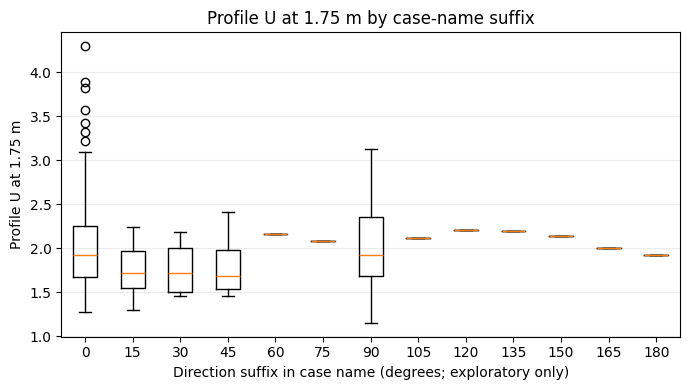

Reminder: verify actual flow direction using each case's .p3d forcing.


In [46]:
def parse_direction_suffix(case_name):
    match = re.search(r"_d(\d+)$", str(case_name))
    return int(match.group(1)) if match else np.nan

case_summary["direction_suffix_deg"] = case_summary["case"].map(parse_direction_suffix)
direction_summary = (
    case_summary.dropna(subset=["direction_suffix_deg"])
    .groupby("direction_suffix_deg")
    .agg(
        cases=("case", "nunique"),
        U_1p75_median=("profile_U_at_1p75m", "median"),
        U_1p75_q25=("profile_U_at_1p75m", lambda x: x.quantile(0.25)),
        U_1p75_q75=("profile_U_at_1p75m", lambda x: x.quantile(0.75)),
        TKE_1p75_median=("profile_TKE_at_1p75m", "median")
    ).reset_index().sort_values("direction_suffix_deg")
)
display(direction_summary)

if not direction_summary.empty:
    directions = sorted(case_summary["direction_suffix_deg"].dropna().unique())
    box_data = [
        case_summary.loc[case_summary["direction_suffix_deg"] == d,
                         "profile_U_at_1p75m"].dropna().to_numpy()
        for d in directions
    ]
    fig, ax = plt.subplots(figsize=(7, 4))
    boxplot_kwargs = {"tick_labels": [str(int(d)) for d in directions]} if tuple(int(x) for x in matplotlib.__version__.split(".")[:2]) >= (3, 9) else {"labels": [str(int(d)) for d in directions]}
    ax.boxplot(box_data, **boxplot_kwargs)
    ax.set_xlabel("Direction suffix in case name (degrees; exploratory only)")
    ax.set_ylabel("Profile U at 1.75 m")
    ax.set_title("Profile U at 1.75 m by case-name suffix")
    ax.grid(True, axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
    plt.close(fig)
else:
    warnings.warn("No direction suffixes were parsed; inspect case names and parsing logic.")

print("Reminder: verify actual flow direction using each case's .p3d forcing.")


## 13. Diagnose `cdz` missingness by case, position, and gap length

cdz gap diagnostic excludes z=0 because it is not a rooftop-related profile level.


,count,mean,std,min,25%,50%,75%,max
cdz_missing_count,314.0,30.356688,21.800581,0.00,0.00,47.000000,47.000000,67.000000
cdz_missing_fraction,314.0,0.237162,0.170317,0.00,0.00,0.367188,0.367188,0.523438
cdz_missing_z_min,222.0,18.281532,5.712089,6.25,16.25,16.250000,16.250000,39.250000
cdz_missing_z_max,222.0,39.250000,0.000000,39.25,39.25,39.250000,39.250000,39.250000
cdz_longest_consecutive_gap_rows,314.0,30.356688,21.800581,0.00,0.00,47.000000,47.000000,67.000000


,case,cdz_missing_count,cdz_missing_fraction,cdz_missing_z_min,cdz_missing_z_max,cdz_longest_consecutive_gap_rows
68,CA-Sunset,67,0.523438,6.25,39.25,67
308,US-WestPhoenix,65,0.507812,7.25,39.25,65
47,AU-Preston,63,0.492188,8.25,39.25,63
50,AU-SurreyHills,55,0.429688,12.25,39.25,55
0,AR-BA-U1_d00,47,0.367188,16.25,39.25,47
204,SG-Boo-U2_d00,47,0.367188,16.25,39.25,47
191,NP-NP-U1_d00,47,0.367188,16.25,39.25,47
192,NP-NP-U2_d00,47,0.367188,16.25,39.25,47
195,RU-MOS-U1_d00,47,0.367188,16.25,39.25,47
196,RU-MOS-U1_d90,47,0.367188,16.25,39.25,47


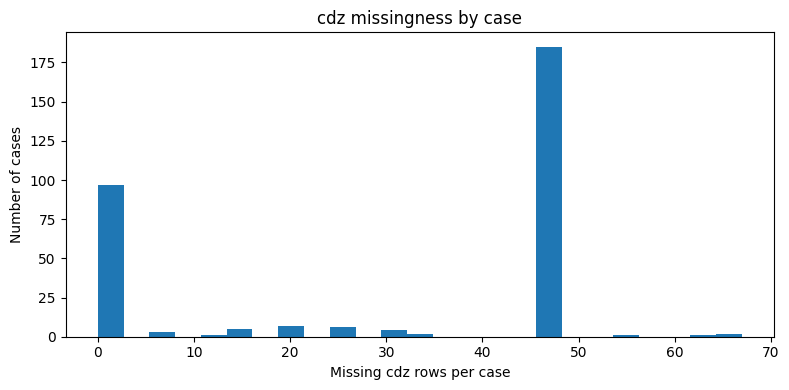

In [47]:
if "cdz" not in clean.columns:
    print("The `cdz` column is not present in these profile CSVs.")
else:
    cdz_rows = []
    for case, group in clean.loc[~np.isclose(clean["z"], 0)].sort_values("z").groupby("case"):
        is_missing = group["cdz"].isna().to_numpy()
        missing_positions = group.loc[group["cdz"].isna(), "z"].to_list()

        # Longest consecutive run of missing cdz rows in vertical order.
        longest_run = current_run = 0
        for value in is_missing:
            if value:
                current_run += 1
                longest_run = max(longest_run, current_run)
            else:
                current_run = 0

        cdz_rows.append({
            "case": case,
            "cdz_missing_count": int(is_missing.sum()),
            "cdz_missing_fraction": float(is_missing.mean()),
            "cdz_missing_z_min": min(missing_positions) if missing_positions else np.nan,
            "cdz_missing_z_max": max(missing_positions) if missing_positions else np.nan,
            "cdz_longest_consecutive_gap_rows": int(longest_run),
        })

    cdz_gap_by_case = pd.DataFrame(cdz_rows)
    print("cdz gap diagnostic excludes z=0 because it is not a rooftop-related profile level.")
    display(cdz_gap_by_case.describe().T)
    display(cdz_gap_by_case.sort_values("cdz_missing_count", ascending=False).head(15))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(cdz_gap_by_case["cdz_missing_count"], bins=25)
    ax.set_xlabel("Missing cdz rows per case")
    ax.set_ylabel("Number of cases")
    ax.set_title("cdz missingness by case")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


## 14. Case-level Spearman correlations (not pooled height rows)

,profile_U_at_1p75m,profile_TKE_at_1p75m,profile_U_mean_all_heights,profile_U_max_all_heights,profile_TKE_mean_all_heights,profile_TKE_max_all_heights
profile_U_at_1p75m,1.000,0.665,0.495,0.394,0.390,0.347
profile_TKE_at_1p75m,0.665,1.000,0.599,0.507,0.746,0.649
profile_U_mean_all_heights,0.495,0.599,1.000,0.962,0.766,0.871
profile_U_max_all_heights,0.394,0.507,0.962,1.000,0.767,0.872
profile_TKE_mean_all_heights,0.390,0.746,0.766,0.767,1.000,0.922
profile_TKE_max_all_heights,0.347,0.649,0.871,0.872,0.922,1.000


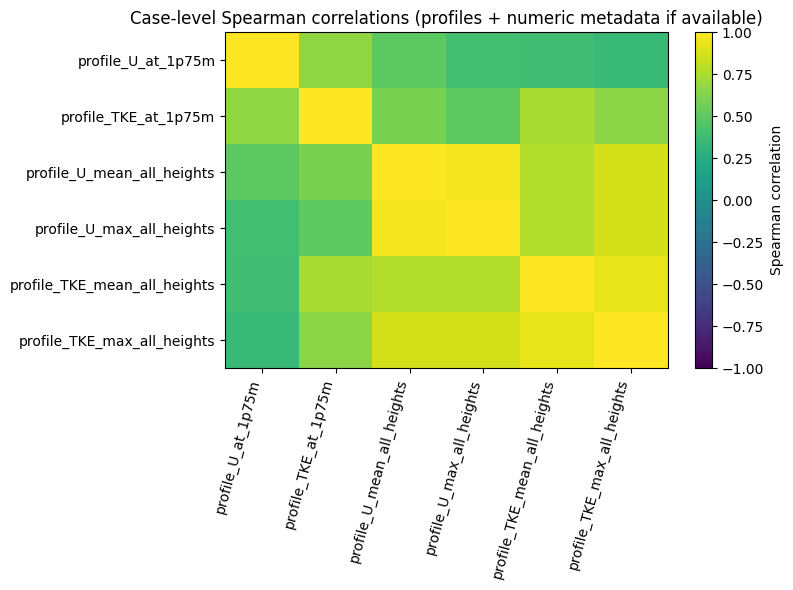

No numeric morphology/density metadata columns detected. Upload the official catalog to enable these correlations.


In [48]:
# Use one row per case to avoid treating vertical levels as independent observations.
# Include numeric metadata (e.g. plan area density or mean building height) if catalog join supplied it.
metadata_candidates = [
    c for c in inventory.columns
    if any(token in c.lower() for token in [
        "plan_area", "density", "lambda", "mean_height", "building_height",
        "height_mean", "height_std", "std_height", "lp", "lf"
    ])
]
numeric_metadata_cols = []
for col in metadata_candidates:
    numeric_values = pd.to_numeric(inventory[col], errors="coerce")
    if numeric_values.notna().sum() > 2 and numeric_values.nunique(dropna=True) > 1:
        numeric_metadata_cols.append(col)
        case_summary[col] = case_summary["case"].map(
            inventory.drop_duplicates("case").set_index("case")[col]
        )

case_level_columns = [
    c for c in [
        "profile_U_at_1p75m", "profile_TKE_at_1p75m",
        "profile_U_mean_all_heights", "profile_U_max_all_heights",
        "profile_TKE_mean_all_heights", "profile_TKE_max_all_heights"
    ] + numeric_metadata_cols if c in case_summary.columns
]
case_level_corr = case_summary[case_level_columns].corr(method="spearman")
display(case_level_corr.round(3))

fig, ax = plt.subplots(figsize=(max(8, len(case_level_corr.columns) * 0.8),
                                max(6, len(case_level_corr.index) * 0.65)))
im = ax.imshow(case_level_corr, vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(case_level_corr.columns)))
ax.set_xticklabels(case_level_corr.columns, rotation=75, ha="right")
ax.set_yticks(range(len(case_level_corr.index)))
ax.set_yticklabels(case_level_corr.index)
ax.set_title("Case-level Spearman correlations (profiles + numeric metadata if available)")
fig.colorbar(im, ax=ax, label="Spearman correlation")
plt.tight_layout()
plt.show()
plt.close(fig)

if not numeric_metadata_cols:
    print("No numeric morphology/density metadata columns detected. Upload the official catalog to enable these correlations.")
else:
    print("Numeric metadata included:", numeric_metadata_cols)


## 15. Physics checks: `Mom = Tuw + Duw` and `Km = -Mom/uGrad`

In [49]:
physics_results = {}

if all(c in clean.columns for c in ["Mom", "Tuw", "Duw"]):
    check = clean[["Mom", "Tuw", "Duw"]].dropna()
    diff = (check["Mom"] - (check["Tuw"] + check["Duw"])).abs()
    physics_results["Mom_equals_Tuw_plus_Duw"] = {
        "rows_checked": len(check),
        "median_absolute_difference": float(diff.median()) if len(diff) else np.nan,
        "mean_absolute_difference": float(diff.mean()) if len(diff) else np.nan,
        "max_absolute_difference": float(diff.max()) if len(diff) else np.nan,
        "within_1e-6_count": int((diff <= 1e-6).sum()),
    }
else:
    print("Skipping Mom = Tuw + Duw: one or more columns are absent.")

if all(c in clean.columns for c in ["Km", "Mom", "uGrad"]):
    check_km = clean[["Km", "Mom", "uGrad"]].dropna()
    check_km = check_km[check_km["uGrad"] != 0].copy()
    expected_km = -check_km["Mom"] / check_km["uGrad"]
    diff_km = (check_km["Km"] - expected_km).abs()
    physics_results["Km_equals_negative_Mom_over_uGrad"] = {
        "rows_checked": len(check_km),
        "median_absolute_difference": float(diff_km.median()) if len(diff_km) else np.nan,
        "mean_absolute_difference": float(diff_km.mean()) if len(diff_km) else np.nan,
        "max_absolute_difference": float(diff_km.max()) if len(diff_km) else np.nan,
        "within_1e-6_count": int((diff_km <= 1e-6).sum()),
    }
else:
    print("Skipping Km = -Mom/uGrad: one or more columns are absent.")

display(pd.DataFrame(physics_results).T)
print("Interpretation: use tolerances and inspect variable definitions/rounding; exact floating-point equality is not expected.")


,rows_checked,median_absolute_difference,mean_absolute_difference,max_absolute_difference,within_1e-6_count
Mom_equals_Tuw_plus_Duw,40192.0,2.081668e-17,5.079545e-17,4.440892e-16,40192.0
Km_equals_negative_Mom_over_uGrad,39878.0,1.154632e-14,2.532424e-10,9.212206e-06,39877.0


Interpretation: use tolerances and inspect variable definitions/rounding; exact floating-point equality is not expected.


## 16. Check whether profiles appear normalized by `u*`

In [50]:
# The handbook states that profile CSV variables are already normalized by u*.
# This is only a rough comparison: profile U at z=1.75 m is not identical to the 2D map statistic.
for variable in ["U", "u", "v", "w", "TKE"]:
    if variable in clean.columns:
        series = clean[variable].dropna()
        print(
            f"{variable}: n={len(series):,}, median={series.median():.5g}, "
            f"p95={series.quantile(0.95):.5g}, min={series.min():.5g}, max={series.max():.5g}"
        )

u175 = case_summary["profile_U_at_1p75m"].dropna()
if len(u175):
    observed_median = float(u175.median())
    print(f"Median profile U at 1.75 m: {observed_median:.4f}")
    print(f"Handbook rough realistic map-based median U/u*: {HANDBOOK_REALISTIC_MEDIAN_U175:.2f}")
    print(f"Difference (profile median - map-based reference): {observed_median - HANDBOOK_REALISTIC_MEDIAN_U175:.4f}")
    print("Interpret as a rough sanity check only; profile and spatial-map statistics are not exactly the same quantity.")
print("\nScale diagnostics cannot prove normalization without raw dimensional source values.")
print("Do not divide by u* again unless the data contract confirms the values are raw dimensional values.")


U: n=40,192, median=6.1861, p95=11.776, min=0.98103, max=19.319
u: n=40,192, median=2.901, p95=11.109, min=-0.77855, max=19.318
v: n=40,192, median=0.73613, p95=9.8199, min=0.022312, max=17.886
w: n=40,192, median=-1.4042e-09, p95=2.3971e-09, min=-0.0047151, max=0.00015453
TKE: n=40,192, median=2.4954, p95=3.6716, min=-4.0303, max=5.1568
Median profile U at 1.75 m: 1.9165
Handbook rough realistic map-based median U/u*: 1.83
Difference (profile median - map-based reference): 0.0865
Interpret as a rough sanity check only; profile and spatial-map statistics are not exactly the same quantity.

Scale diagnostics cannot prove normalization without raw dimensional source values.
Do not divide by u* again unless the data contract confirms the values are raw dimensional values.


## 17. Findings and conclusions

In [51]:
valid_u175 = case_summary["profile_U_at_1p75m"].dropna()
valid_tke175 = case_summary["profile_TKE_at_1p75m"].dropna()

print("=== REALISTIC PROFILE EDA — KEY FINDINGS ===")
print(f"Profile CSVs: {len(profile_files)}")
print(f"Unique cases: {raw['case'].nunique()}")
print(f"Raw rows: {len(raw):,}")
print(f"Analysis rows after dropping final level: {len(clean):,}")
print(f"Duplicate complete raw rows: {int(raw.duplicated().sum())}")
print(f"Variables with missing values: {len(missing_table)}")
print(f"Cases with interpolated U at 1.75 m: {len(valid_u175)}")
if len(valid_u175):
    print(f"U at 1.75 m — median across cases: {valid_u175.median():.4f}")
    print(f"U at 1.75 m — IQR: {valid_u175.quantile(.25):.4f} to {valid_u175.quantile(.75):.4f}")
if len(valid_tke175):
    print(f"TKE at 1.75 m — median across cases: {valid_tke175.median():.4f}")
print("\nQC notes:")
print("- Direction suffixes are exploratory; confirm actual direction from .p3d.")
print("- Known short-run/direction-offset cases need forcing/time-series verification.")
print("- Spatial map checks require _topo and _ped.nc files.")
print("- A metadata/catalog join is required for official city and split_group analyses.")


=== REALISTIC PROFILE EDA — KEY FINDINGS ===
Profile CSVs: 314
Unique cases: 314
Raw rows: 40,820
Analysis rows after dropping final level: 40,192
Duplicate complete raw rows: 0
Variables with missing values: 16
Cases with interpolated U at 1.75 m: 314
U at 1.75 m — median across cases: 1.9165
U at 1.75 m — IQR: 1.6550 to 2.2093
TKE at 1.75 m — median across cases: 1.8929

QC notes:
- Direction suffixes are exploratory; confirm actual direction from .p3d.
- Known short-run/direction-offset cases need forcing/time-series verification.
- Spatial map checks require _topo and _ped.nc files.
- A metadata/catalog join is required for official city and split_group analyses.


## 18. Export compact EDA tables and cleaned profile data

In [52]:
inventory.to_csv(OUTPUT_DIR / "case_inventory.csv", index=False)
z0_audit.to_csv(OUTPUT_DIR / "z0_row_audit.csv", index=False)
missing_table.to_csv(OUTPUT_DIR / "missing_values_summary.csv")
case_summary.to_csv(OUTPUT_DIR / "case_profile_summary.csv", index=False)
direction_summary.to_csv(OUTPUT_DIR / "direction_suffix_summary.csv", index=False)
case_level_corr.to_csv(OUTPUT_DIR / "case_level_spearman_correlation.csv")
if "cdz_gap_by_case" in globals():
    cdz_gap_by_case.to_csv(OUTPUT_DIR / "cdz_gap_by_case.csv", index=False)
if "z0_audit" in globals():
    z0_audit.to_csv(OUTPUT_DIR / "z0_row_audit.csv", index=False)
if "physics_results" in globals():
    pd.DataFrame(physics_results).T.to_csv(OUTPUT_DIR / "physics_checks.csv")

# Export cleaned combined profiles for local analysis only.
# It is large and should NOT be committed to Git.
clean.to_csv(OUTPUT_DIR / "combined_realistic_profiles_cleaned.csv", index=False)

report_text = f'''# UrbanTales Realistic Profile EDA — Run Summary

- ZIP file: {ZIP_PATH}
- Profile CSV files: {len(profile_files)}
- Unique cases: {raw["case"].nunique()}
- Raw combined shape: {raw.shape}
- Duplicate complete raw rows: {int(raw.duplicated().sum())}
- Rows after dropping final profile level per case: {len(clean)}
- Variables with missing values: {len(missing_table)}
- Cases with interpolated U at z=1.75 m: {case_summary["profile_U_at_1p75m"].notna().sum()}\n- Empty z=0 rows dropped: {int(z0_audit["empty_measurement_row_dropped"].sum()) if "empty_measurement_row_dropped" in z0_audit else 0}\n- Catalog metadata joined: {"yes" if "split_group" in inventory.columns else "no"}

## Scope limits
This run analyses profile CSVs only. Spatial map checks need _topo and _ped.nc; true wind direction needs .p3d; run duration/stationarity needs .ts.nc. Official city and split_group fields need the official metadata/catalog.
'''
(OUTPUT_DIR / "UrbanTales_Realistic_EDA_Report.md").write_text(report_text, encoding="utf-8")

print("Saved files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")


Saved files:
UrbanTales_Realistic_EDA_Report.md: 669 bytes
case_inventory.csv: 34,661 bytes
case_level_spearman_correlation.csv: 897 bytes
case_profile_summary.csv: 51,948 bytes
cdz_gap_by_case.csv: 11,565 bytes
combined_realistic_profiles_cleaned.csv: 22,961,462 bytes
direction_suffix_summary.csv: 1,156 bytes
missing_values_summary.csv: 255 bytes
physics_checks.csv: 333 bytes
z0_row_audit.csv: 9,411 bytes


## 19. Download the results bundle (Colab only; safe outside Colab)

In [53]:
RESULTS_ZIP = Path("UrbanTales_Realistic_EDA_Results.zip")
with zipfile.ZipFile(RESULTS_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in OUTPUT_DIR.iterdir():
        if path.is_file():
            zf.write(path, arcname=f"{OUTPUT_DIR.name}/{path.name}")

print("Created:", RESULTS_ZIP.resolve())
try:
    from google.colab import files as colab_files
    colab_files.download(str(RESULTS_ZIP))
except Exception as exc:
    print("Automatic download is only available in Google Colab.")
    print("The ZIP is saved at:", RESULTS_ZIP.resolve())
    print("Reason:", exc)


Created: /Users/neerajsingh/Urban-Microclimate-Modelling/pipeline/S04_eda/Realistic Urban Neighbourhoods/UrbanTales_Realistic_EDA_Results.zip
Automatic download is only available in Google Colab.
The ZIP is saved at: /Users/neerajsingh/Urban-Microclimate-Modelling/pipeline/S04_eda/Realistic Urban Neighbourhoods/UrbanTales_Realistic_EDA_Results.zip
Reason: No module named 'google.colab'


## 20. Final interpretation checklist

- [ ] Verify the ZIP has 314 profile cases and expected rows per file.
- [ ] Review the `z=0` diagnostics; do not drop rows without checking their values.
- [ ] Use interpolated profile `U` at 1.75 m rather than an all-height mean as the pedestrian-height profile comparison.
- [ ] Review `cdz` missingness by case and height.
- [ ] Investigate both physics identities with tolerances.
- [ ] Use official catalog metadata for city, subset, and `split_group`.
- [ ] Confirm actual wind direction from `.p3d`.
- [ ] Use `_topo`, `_ped.nc`, and `_ts.nc` for map alignment, map targets, and simulation duration/stationarity checks.
- [ ] Do not commit the large combined CSV or raw data to Git.
- [ ] Run all cells from a clean runtime before opening a PR.
